<a href="https://colab.research.google.com/github/Henrietta-quarshie7/Elevvo_internshp_models/blob/main/Student_Score_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student Performance Prediction Using Linear Regression

## Project Overview

This project aims to develop a Machine Learning model that predicts students' examination scores based on their study hours.

The project uses the Student Performance Factors dataset obtained from Kaggle. Data cleaning, exploratory data analysis and visualization will be performed to understand the relationship between study hours and exam scores.

A Linear Regression algorithm will be trained using the dataset to estimate students' examination scores.

## Objectives
- Load and explore the student performance dataset.
- Clean the dataset and handle missing values.
- Visualize the relationship between study hours and exam scores.
- Split the dataset into training and testing sets.
- Train a Linear Regression model.
- Predict examination scores based on study hours.
- Evaluate model performance using appropriate metrics.

## Tools and Technologies
- Python
- Pandas
- Matplotlib
- Scikit-learn
- Google Colab
- GitHub

## Expected Outcome

A trained Linear Regression model capable of estimating students' examination scores based on their study hours.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [13]:
import pandas as pd
import os
file_path = '/content/drive/MyDrive/StudentPerformanceFactors.csv'
df = pd.read_csv(file_path)

In [45]:
#data manipulation
import numpy as np
#data visualization
import matplotlib.pyplot as plt
#ML
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
#evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [17]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [18]:
df.tail()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68
6606,15,67,Medium,Low,Yes,9,94,Medium,Yes,0,Medium,Medium,Public,Positive,4,No,Postgraduate,Near,Male,64


In [20]:
print(df.columns.tolist())

['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [23]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [25]:
#Check for null values
print(df.isnull().sum())

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


In [28]:
print(df.duplicated().sum())

0


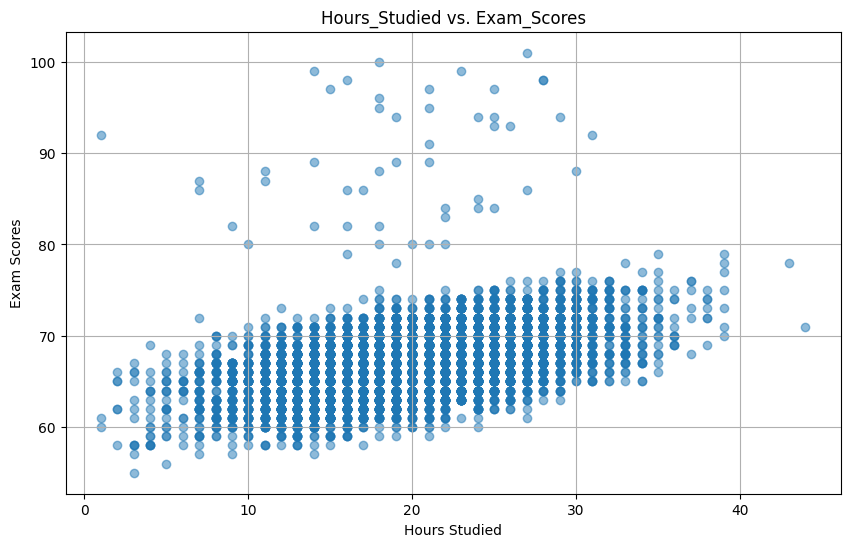

In [31]:
plt.figure(figsize=(10,6))
plt.scatter(df['Hours_Studied'],df['Exam_Score'], alpha=0.5)
plt.title('Hours_Studied vs. Exam_Scores')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Scores')
plt.grid(True)
plt.show()

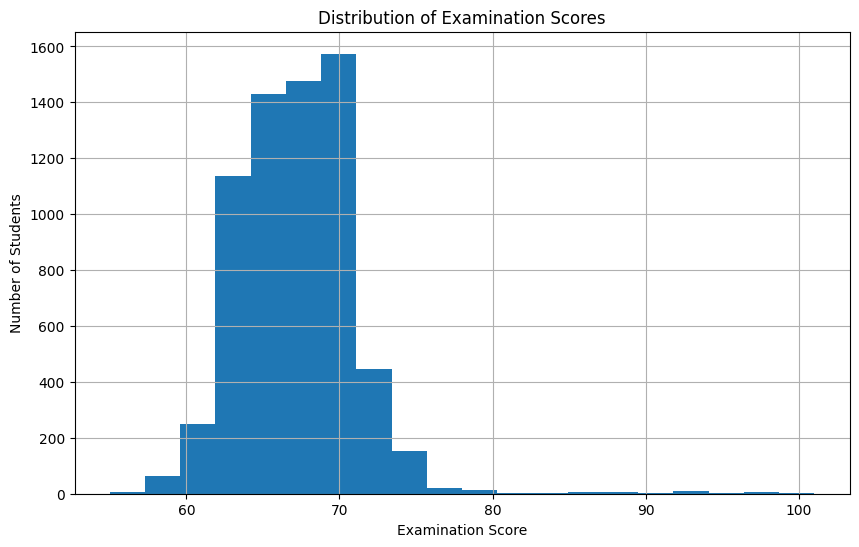

In [30]:
plt.figure(figsize=(10, 6))

plt.hist(df['Exam_Score'], bins=20)

plt.title('Distribution of Examination Scores')
plt.xlabel('Examination Score')
plt.ylabel('Number of Students')

plt.grid(True)
plt.show()

In [32]:
correlation = df['Hours_Studied'].corr(df['Exam_Score'])
print(f"Correlation between Hours_Studied and Exam_Score: {correlation}")

Correlation between Hours_Studied and Exam_Score: 0.4454549540752825


In [37]:
X = df[['Hours_Studied']]
y = df['Exam_Score']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Check
print('Training data: ', X_train.shape)
print('Testing data: ', X_test.shape)

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Training data:  (5285, 1)
Testing data:  (1322, 1)
Model trained successfully!


In [40]:
# Prediction
y_pred = model.predict(X_test)
print('Predicted scores: ', y_pred[:10])

Predicted scores:  [67.22454236 67.79587985 67.5102111  64.9391924  67.5102111  67.5102111
 72.08091101 68.36721734 66.36753612 66.08186738]


In [42]:
# Compare
comparison = pd.DataFrame({'Actual score': y_test.values, 'Predicted': y_pred})
print(comparison.head(10))

   Actual score  Predicted
0            65  67.224542
1            65  67.795880
2            71  67.510211
3            64  64.939192
4            66  67.510211
5            66  67.510211
6            72  72.080911
7            66  68.367217
8            70  66.367536
9            70  66.081867


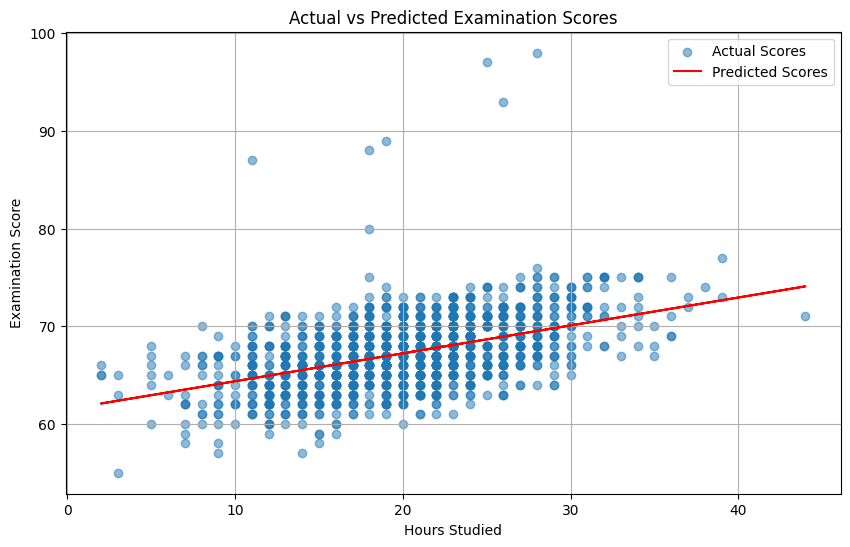

In [43]:
# Visualize predictions
plt.figure(figsize=(10, 6))

plt.scatter(
    X_test['Hours_Studied'],
    y_test,
    label='Actual Scores',
    alpha=0.5
)

plt.plot(
    X_test['Hours_Studied'],
    y_pred,
    color='red',
    label='Predicted Scores'
)

plt.title('Actual vs Predicted Examination Scores')
plt.xlabel('Hours Studied')
plt.ylabel('Examination Score')

plt.legend()
plt.grid(True)
plt.show()

In [47]:
# Evaluate
# MAE
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error:", mae)

# MSE
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

# RMSE
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

# r2
r2 = r2_score(y_test, y_pred)
print("R-squared:", r2)

Mean Absolute Error: 2.4475687452945643
Mean Squared Error: 10.85592128879332
Root Mean Squared Error: 3.294832513010839
R-squared: 0.2319868674542106


In [50]:
# Test with input
study_hours = pd.DataFrame({
    'Hours_Studied': [20]
})

predicted_score = model.predict(study_hours)

print("Study Hours: 5")
print("Predicted Examination Score:", predicted_score[0])

Study Hours: 5
Predicted Examination Score: 67.22454235790597
